# Comptage de mots : Python, MapReduce, Hadoop, Spark

Comparaison de 4 méthodes sur 3 fichiers (un mot par ligne) :

1. Python simple (dictionnaire)
2. Pseudo-MapReduce Python (`mapper` → `shuffle` → `reducer`)
3. Hadoop MapReduce (`wordcount` sur HDFS + YARN)
4. Apache Spark avec PySpark (RDD et DataFrame)

## 0. Environnement

Hadoop 3.4.1 tourne dans Docker (`hadoop/docker-compose.yml`). Pour le démarrer :
```bash
docker compose -f hadoop/docker-compose.yml up -d
```

In [1]:
import os, sys, platform, random, time, statistics, subprocess, tracemalloc
from collections import defaultdict, Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
DATA.mkdir(exist_ok=True)
COMPOSE = ["docker", "compose", "-f", "hadoop/docker-compose.yml"]

print("Python   :", sys.version.split()[0])
print("Système  :", platform.platform())
print("CPU      :", os.cpu_count(), "cœurs logiques")
print(subprocess.run(COMPOSE + ["exec", "-T", "namenode", "hadoop", "version"],
                     capture_output=True, text=True).stdout.splitlines()[0])

Python   : 3.12.15
Système  : Windows-11-10.0.26200-SP0
CPU      : 8 cœurs logiques


Hadoop 3.4.1


## 1. Fichiers de test

Mots tirés au hasard avec les fréquences du `mots.txt` du rapport (graine fixe).

In [2]:
# Vocabulaire et poids issus du résultat de la version 1 du rapport
POIDS = {"chat": 24, "chien": 11, "arbre": 7, "fleur": 7, "maison": 5, "soleil": 5,
         "montagne": 5, "livre": 4, "ciel": 4, "mer": 3, "lune": 3, "route": 3,
         "oiseau": 2, "jardin": 1, "voiture": 1}

TAILLES = {"petit": 1_000, "moyen": 100_000, "grand": 10_000_000}

def generer_fichier(chemin, n, graine=42, bloc=1_000_000):
    rng = random.Random(graine)
    mots, poids = list(POIDS), list(POIDS.values())
    with open(chemin, "w", encoding="utf-8", newline="\n") as f:
        reste = n
        while reste > 0:
            k = min(bloc, reste)
            f.write("\n".join(rng.choices(mots, weights=poids, k=k)) + "\n")
            reste -= k

FICHIERS = {}
for nom, n in TAILLES.items():
    chemin = DATA / f"{nom}.txt"
    if not chemin.exists():
        generer_fichier(chemin, n)
    FICHIERS[nom] = chemin

pd.DataFrame([{"fichier": p.name, "lignes": TAILLES[k], "taille (Mo)": round(p.stat().st_size / 1e6, 2)}
              for k, p in FICHIERS.items()])

,fichier,lignes,taille (Mo)
0,petit.txt,1000,0.01
1,moyen.txt,100000,0.59
2,grand.txt,10000000,59.18


In [3]:
# Aperçu du petit fichier
print(FICHIERS["petit"].read_text(encoding="utf-8").splitlines()[:10])

['soleil', 'chat', 'chat', 'chat', 'montagne', 'soleil', 'lune', 'chat', 'arbre', 'chat']


## 2. Méthodes

### Méthode 1 : Python simple

In [4]:
def compter_occurrences(fichier):
    with open(fichier, "r", encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

def methode1(fichier):
    return compter_occurrences(fichier)

### Méthode 2 : Pseudo-MapReduce

In [5]:
def mapper(ligne):
    mots = ligne.strip().split()
    return [(mot, 1) for mot in mots]

def shuffle(mapped_data):
    grouped = defaultdict(list)
    for mot, valeur in mapped_data:
        grouped[mot].append(valeur)
    return grouped

def reducer(grouped_data):
    reduced = {}
    for mot, valeurs in grouped_data.items():
        reduced[mot] = sum(valeurs)
    return reduced

def methode2(fichier):
    mapped = []
    with open(fichier, "r", encoding="utf-8") as f:
        for ligne in f:
            mapped.extend(mapper(ligne))
    grouped = shuffle(mapped)
    return reducer(grouped)

### Méthode 3 : Hadoop MapReduce

Copie dans HDFS, job `wordcount`, lecture du résultat. On chronomètre la copie et le job séparément.

In [6]:
JAR = "/opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-3.4.1.jar"
HDFS_DIR = "/user/hadoop/wordcount"

def hdfs(*args, check=True):
    # Exécute une commande dans le conteneur namenode (client Hadoop)
    r = subprocess.run(COMPOSE + ["exec", "-T", "namenode", *args], capture_output=True, text=True)
    if check and r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return r.stdout

def methode3(fichier, details=False):
    nom = Path(fichier).stem
    entree, sortie = f"{HDFS_DIR}/input/{nom}", f"{HDFS_DIR}/output/{nom}"
    hdfs("hdfs", "dfs", "-rm", "-r", "-f", "-skipTrash", entree, sortie)
    hdfs("hdfs", "dfs", "-mkdir", "-p", entree)

    t0 = time.perf_counter()
    hdfs("hdfs", "dfs", "-put", f"/donnees/{Path(fichier).name}", entree + "/")
    t1 = time.perf_counter()
    hdfs("hadoop", "jar", JAR, "wordcount", entree, sortie)
    t2 = time.perf_counter()

    resultat = {}
    for ligne in hdfs("hdfs", "dfs", "-cat", f"{sortie}/part-r-00000").splitlines():
        mot, nb = ligne.split("\t")
        resultat[mot] = int(nb)
    if details:
        return resultat, {"copie HDFS": t1 - t0, "job MapReduce": t2 - t1}
    return resultat

## 3. Vérification des résultats

In [7]:
for nom, chemin in FICHIERS.items():
    with open(chemin, encoding="utf-8") as f:
        reference = Counter(f.read().split())
    r1, r2, r3 = methode1(chemin), methode2(chemin), methode3(chemin)
    ok = (r1 == reference) and (r2 == reference) and (r3 == reference)
    print(f"{nom:6s} : {sum(reference.values()):>10,} mots, {len(reference)} mots distincts -> "
          f"{'résultats identiques ✔' if ok else 'DIFFÉRENCE ✘'}")

petit  :      1,000 mots, 15 mots distincts -> résultats identiques ✔


moyen  :    100,000 mots, 15 mots distincts -> résultats identiques ✔


grand  : 10,000,000 mots, 15 mots distincts -> résultats identiques ✔


In [8]:
# Résultat sur le petit fichier, trié comme dans le rapport
r = methode1(FICHIERS["petit"])
pd.Series(r, name="occurrences").sort_values(ascending=False).to_frame().T

,chat,chien,arbre,fleur,soleil,montagne,maison,mer,ciel,livre,route,lune,oiseau,voiture,jardin
occurrences,277,109,90,82,66,63,60,50,43,41,34,30,27,16,12


## 4. Mesures

Médiane de 7 exécutions (3 pour le grand fichier). Le démarrage du cluster Hadoop n'est pas compté.

In [9]:
def chrono(fonction, fichier, repetitions):
    temps = []
    for _ in range(repetitions):
        t0 = time.perf_counter()
        fonction(fichier)
        temps.append(time.perf_counter() - t0)
    return statistics.median(temps), temps

mesures = []
details_hadoop = []
for nom, chemin in FICHIERS.items():
    rep = 3 if nom == "grand" else 7
    for methode, f in [("1. Python simple", methode1), ("2. Pseudo-MapReduce", methode2)]:
        med, brut = chrono(f, chemin, rep)
        mesures.append({"fichier": nom, "N": TAILLES[nom], "méthode": methode, "temps (s)": med,
                        "min (s)": min(brut), "max (s)": max(brut)})
        print(f"{nom:6s} {methode:22s} médiane = {med:.4f} s")

    brut = []
    for _ in range(3):
        _, d = methode3(chemin, details=True)
        brut.append(d["job MapReduce"])
        details_hadoop.append({"fichier": nom, "N": TAILLES[nom], **d})
    mesures.append({"fichier": nom, "N": TAILLES[nom], "méthode": "3. Hadoop MapReduce",
                    "temps (s)": statistics.median(brut), "min (s)": min(brut), "max (s)": max(brut)})
    print(f"{nom:6s} {'3. Hadoop MapReduce':22s} médiane = {statistics.median(brut):.2f} s")

df = pd.DataFrame(mesures)

petit  1. Python simple       médiane = 0.0002 s
petit  2. Pseudo-MapReduce    médiane = 0.0005 s


petit  3. Hadoop MapReduce    médiane = 21.96 s
moyen  1. Python simple       médiane = 0.0119 s


moyen  2. Pseudo-MapReduce    médiane = 0.0371 s


moyen  3. Hadoop MapReduce    médiane = 20.35 s


grand  1. Python simple       médiane = 1.6036 s


grand  2. Pseudo-MapReduce    médiane = 5.2605 s


grand  3. Hadoop MapReduce    médiane = 28.88 s


### Temps (s)

In [10]:
tableau = df.pivot(index="méthode", columns="fichier", values="temps (s)")[list(TAILLES)]
tableau.columns = [f"{c} (N={TAILLES[c]:,})".replace(",", " ") for c in tableau.columns]
tableau.style.format("{:.4f}")

,petit (N=1 000),moyen (N=100 000),grand (N=10 000 000)
méthode,,,
1. Python simple,0.0002,0.0119,1.6036
2. Pseudo-MapReduce,0.0005,0.0371,5.2605
3. Hadoop MapReduce,21.9613,20.3536,28.8764


In [11]:
# Rapport de vitesse par rapport à la méthode 1 (> 1 = plus lent que Python simple)
base = df[df["méthode"] == "1. Python simple"].set_index("fichier")["temps (s)"]
df["× vs méthode 1"] = df.apply(lambda r: r["temps (s)"] / base[r["fichier"]], axis=1)
df["débit (M mots/s)"] = df["N"] / df["temps (s)"] / 1e6
df.pivot(index="méthode", columns="fichier", values=["× vs méthode 1", "débit (M mots/s)"])[
    [(m, f) for m in ["× vs méthode 1", "débit (M mots/s)"] for f in TAILLES]].round(3)

× vs méthode 1                   débit (M mots/s)         \
fichier                      petit     moyen   grand            petit  moyen   
méthode                                                                        
1. Python simple             1.000     1.000   1.000            5.230  8.385   
2. Pseudo-MapReduce          2.359     3.109   3.280            2.217  2.697   
3. Hadoop MapReduce     114860.317  1706.631  18.007            0.000  0.005   

                            
fichier              grand  
méthode                     
1. Python simple     6.236  
2. Pseudo-MapReduce  1.901  
3. Hadoop MapReduce  0.346

### Hadoop : copie HDFS et job

In [12]:
dh = pd.DataFrame(details_hadoop).groupby(["fichier", "N"], sort=False).median().round(2)
dh["total (s)"] = dh.sum(axis=1)
dh

,,copie HDFS,job MapReduce,total (s)
fichier,N,,,
petit,1000,2.22,21.96,24.18
moyen,100000,2.03,20.35,22.38
grand,10000000,4.73,28.88,33.61


### Mémoire maximale (Python, en Mo)

In [13]:
memoire = []
for nom, chemin in FICHIERS.items():
    for methode, f in [("1. Python simple", methode1), ("2. Pseudo-MapReduce", methode2)]:
        tracemalloc.start()
        f(chemin)
        _, pic = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        memoire.append({"fichier": nom, "méthode": methode, "pic mémoire (Mo)": pic / 1e6})
dm = pd.DataFrame(memoire).pivot(index="méthode", columns="fichier", values="pic mémoire (Mo)")[list(TAILLES)]
dm.round(2)

fichier,petit,moyen,grand
méthode,,,
1. Python simple,0.07,6.00,607.63
2. Pseudo-MapReduce,0.07,11.78,1193.62


## 5. Graphiques

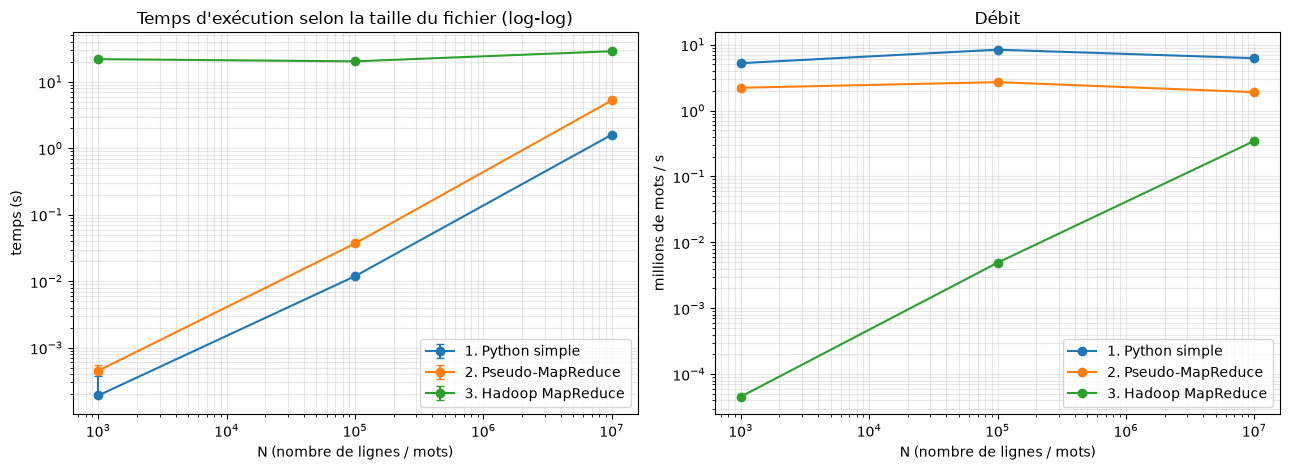

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
couleurs = {"1. Python simple": "tab:blue", "2. Pseudo-MapReduce": "tab:orange", "3. Hadoop MapReduce": "tab:green"}

for methode, g in df.groupby("méthode"):
    g = g.sort_values("N")
    axes[0].errorbar(g["N"], g["temps (s)"],
                     yerr=[g["temps (s)"] - g["min (s)"], g["max (s)"] - g["temps (s)"]],
                     marker="o", capsize=3, label=methode, color=couleurs[methode])
    axes[1].plot(g["N"], g["débit (M mots/s)"], marker="o", label=methode, color=couleurs[methode])

axes[0].set(xscale="log", yscale="log", xlabel="N (nombre de lignes / mots)", ylabel="temps (s)",
            title="Temps d'exécution selon la taille du fichier (log-log)")
axes[1].set(xscale="log", yscale="log", xlabel="N (nombre de lignes / mots)", ylabel="millions de mots / s",
            title="Débit")
for ax in axes:
    ax.grid(True, which="both", alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()

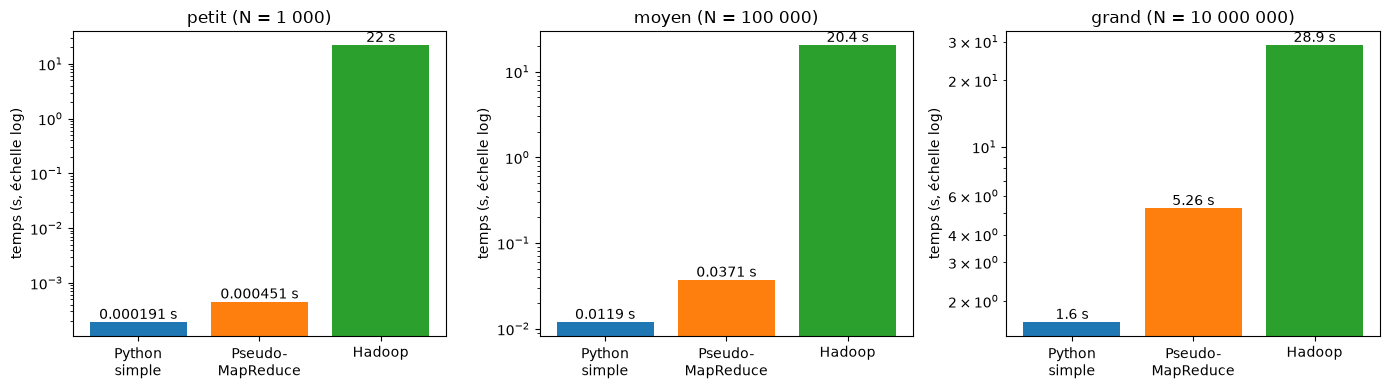

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, nom in zip(axes, TAILLES):
    g = df[df["fichier"] == nom]
    barres = ax.bar(["Python\nsimple", "Pseudo-\nMapReduce", "Hadoop"], g["temps (s)"],
                    color=[couleurs[m] for m in g["méthode"]])
    ax.bar_label(barres, fmt="%.3g s")
    ax.set_title(f"{nom} (N = {TAILLES[nom]:,})".replace(",", " "))
    ax.set_yscale("log")
    ax.set_ylabel("temps (s, échelle log)")
plt.tight_layout()
plt.show()

In [16]:
# Pente en log-log : temps ≈ a·N^b  (b ≈ 1 → coût linéaire ; b ≈ 0 → coût dominé par une constante)
import numpy as np
pentes = {m: np.polyfit(np.log10(g["N"]), np.log10(g["temps (s)"]), 1)[0] for m, g in df.groupby("méthode")}
pd.Series(pentes, name="exposant b (temps ∝ N^b)").round(2).to_frame()

,exposant b (temps ∝ N^b)
1. Python simple,0.98
2. Pseudo-MapReduce,1.02
3. Hadoop MapReduce,0.03


## 6. Bilan des méthodes 1 à 3

- Les 3 méthodes donnent les mêmes résultats.
- **Python simple** est le plus rapide partout (1,6 s pour 10 M mots).
- **Pseudo-MapReduce** : ≈ 3 × plus lent et 2 × plus de mémoire, car il stocke toutes les paires `(mot, 1)`.
- **Hadoop** : ≈ 20 s de coût fixe (lancement du job sur YARN), quelle que soit la taille.
  L'écart avec Python passe de × 115 000 (petit) à × 18 (grand).
- Le grand fichier (60 Mo) tient dans un seul bloc HDFS (128 Mo), donc Hadoop n'utilise qu'un mapper.
  Il n'est utile que si les données dépassent la capacité d'une machine.

## 7. Apache Spark (PySpark)

Spark garde les données en mémoire et parallélise les tâches. Ici en mode local, sur 8 cœurs.

In [17]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avertissement pandas 3 de PySpark, sans effet ici
os.environ["PYSPARK_PYTHON"] = sys.executable          # workers Python = même interpréteur que le notebook
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from operator import add

def demarrer_spark(coeurs="*"):
    return (SparkSession.builder
            .master(f"local[{coeurs}]")
            .appName("comptage-mots")
            .config("spark.driver.memory", "4g")
            .config("spark.ui.showConsoleProgress", "false")
            .getOrCreate())

t0 = time.perf_counter()
spark = demarrer_spark()
spark.sparkContext.setLogLevel("ERROR")
demarrage_spark = time.perf_counter() - t0

sc = spark.sparkContext
jvm = sc._jvm.java.lang.System
print("Spark        :", spark.version)
print("Java         :", jvm.getProperty("java.version"))
print("Master       :", sc.master, "->", sc.defaultParallelism, "tâches en parallèle")
print(f"Démarrage de la session Spark : {demarrage_spark:.2f} s")

Spark        : 4.2.0
Java         : 25.0.1
Master       : local[*] -> 8 tâches en parallèle
Démarrage de la session Spark : 8.09 s


### Méthode 4a : Spark RDD

Même logique que la méthode 2 : `flatMap` → `map` → `reduceByKey`.

In [18]:
def chemin_spark(fichier):
    return Path(fichier).resolve().as_uri()       # file:///C:/... : chemin absolu lisible par la JVM

def methode4_rdd(fichier):
    lignes = sc.textFile(chemin_spark(fichier), minPartitions=sc.defaultParallelism)
    return (lignes.flatMap(lambda ligne: ligne.split())
                  .map(lambda mot: (mot, 1))
                  .reduceByKey(add)
                  .collectAsMap())

### Méthode 4b : Spark DataFrame

Le calcul est fait dans la JVM, sans passer par Python.

In [19]:
def requete_df(fichier):
    return (spark.read.text(chemin_spark(fichier))
                 .select(F.explode(F.split(F.trim("value"), r"\s+")).alias("mot"))
                 .where(F.col("mot") != "")
                 .groupBy("mot").count())

def methode4_df(fichier):
    return {ligne["mot"]: ligne["count"] for ligne in requete_df(fichier).collect()}

# Plan physique : on y voit l'agrégation en deux temps (partial_count puis count),
# séparée par un échange (shuffle) entre partitions
requete_df(FICHIERS["grand"]).explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[mot#2], functions=[count(1)])
   +- Exchange hashpartitioning(mot#2, 200), ENSURE_REQUIREMENTS, [plan_id=19]
      +- HashAggregate(keys=[mot#2], functions=[partial_count(1)])
         +- Filter NOT (mot#2 = )
            +- Generate explode(split(trim(value#0, None), \s+, -1)), false, [mot#2]
               +- FileScan text [value#0] Batched: false, DataFilters: [], Format: Text, Location: InMemoryFileIndex(1 paths)[file:/C:/Users/enzoj/Documents/S9/quaf/data/grand.txt], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<value:string>




### Vérification

In [20]:
for nom, chemin in FICHIERS.items():
    with open(chemin, encoding="utf-8") as f:
        reference = Counter(f.read().split())
    ok_rdd = methode4_rdd(chemin) == reference
    ok_df = methode4_df(chemin) == reference
    print(f"{nom:6s} : RDD {'✔' if ok_rdd else '✘'}   DataFrame {'✔' if ok_df else '✘'}")

petit  : RDD ✔   DataFrame ✔


moyen  : RDD ✔   DataFrame ✔


grand  : RDD ✔   DataFrame ✔


### Mesures

Même protocole que la section 4. Le démarrage de la session Spark n'est pas compté.

In [21]:
methode4_rdd(FICHIERS["petit"]); methode4_df(FICHIERS["petit"])   # échauffement

mesures_spark = []
for nom, chemin in FICHIERS.items():
    rep = 3 if nom == "grand" else 7
    for methode, f in [("4a. Spark RDD", methode4_rdd), ("4b. Spark DataFrame", methode4_df)]:
        med, brut = chrono(f, chemin, rep)
        mesures_spark.append({"fichier": nom, "N": TAILLES[nom], "méthode": methode, "temps (s)": med,
                              "min (s)": min(brut), "max (s)": max(brut)})
        print(f"{nom:6s} {methode:22s} médiane = {med:.4f} s")

df_tout = pd.concat([df[["fichier", "N", "méthode", "temps (s)", "min (s)", "max (s)"]],
                     pd.DataFrame(mesures_spark)], ignore_index=True)
base = df_tout[df_tout["méthode"] == "1. Python simple"].set_index("fichier")["temps (s)"]
df_tout["× vs méthode 1"] = df_tout.apply(lambda r: r["temps (s)"] / base[r["fichier"]], axis=1)
df_tout["débit (M mots/s)"] = df_tout["N"] / df_tout["temps (s)"] / 1e6

petit  4a. Spark RDD          médiane = 15.8911 s


petit  4b. Spark DataFrame    médiane = 0.1721 s


moyen  4a. Spark RDD          médiane = 16.1232 s


moyen  4b. Spark DataFrame    médiane = 0.1999 s


grand  4a. Spark RDD          médiane = 24.3132 s


grand  4b. Spark DataFrame    médiane = 2.8643 s


### Temps (s)

In [22]:
tableau_tout = df_tout.pivot(index="méthode", columns="fichier", values="temps (s)")[list(TAILLES)]
tableau_tout.columns = [f"{c} (N={TAILLES[c]:,})".replace(",", " ") for c in tableau_tout.columns]
tableau_tout.style.format("{:.4f}").highlight_min(axis=0, color="#c6efce")

,petit (N=1 000),moyen (N=100 000),grand (N=10 000 000)
méthode,,,
1. Python simple,0.0002,0.0119,1.6036
2. Pseudo-MapReduce,0.0005,0.0371,5.2605
3. Hadoop MapReduce,21.9613,20.3536,28.8764
4a. Spark RDD,15.8911,16.1232,24.3132
4b. Spark DataFrame,0.1721,0.1999,2.8643


In [23]:
df_tout.pivot(index="méthode", columns="fichier", values=["× vs méthode 1", "débit (M mots/s)"])[
    [(m, f) for m in ["× vs méthode 1", "débit (M mots/s)"] for f in TAILLES]].round(3)

× vs méthode 1                   débit (M mots/s)         \
fichier                      petit     moyen   grand            petit  moyen   
méthode                                                                        
1. Python simple             1.000     1.000   1.000            5.230  8.385   
2. Pseudo-MapReduce          2.359     3.109   3.280            2.217  2.697   
3. Hadoop MapReduce     114860.317  1706.631  18.007            0.000  0.005   
4a. Spark RDD            83112.396  1351.916  15.161            0.000  0.006   
4b. Spark DataFrame        899.994    16.760   1.786            0.006  0.500   

                            
fichier              grand  
méthode                     
1. Python simple     6.236  
2. Pseudo-MapReduce  1.901  
3. Hadoop MapReduce  0.346  
4a. Spark RDD        0.411  
4b. Spark DataFrame  3.491

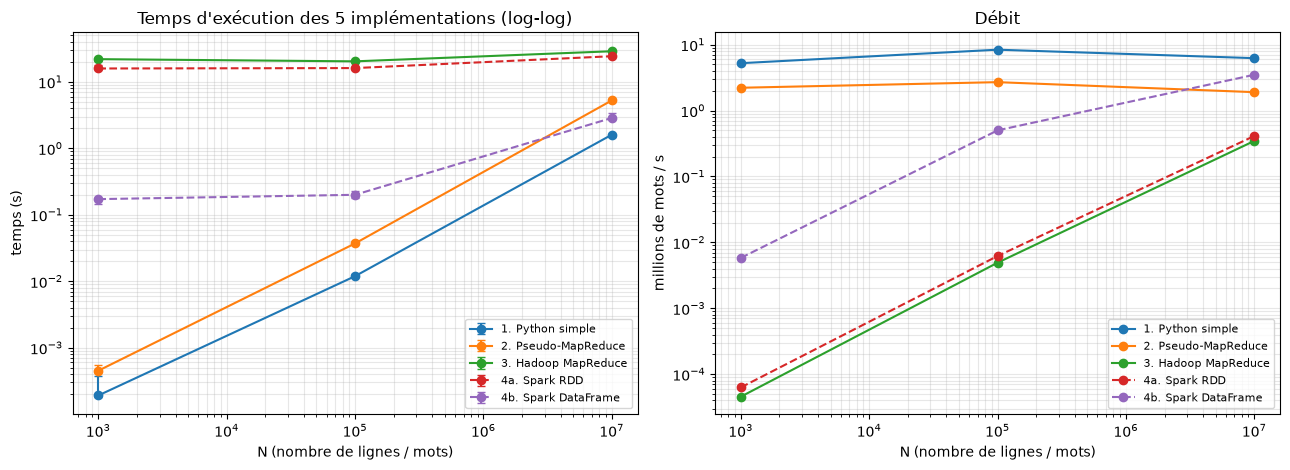

In [24]:
couleurs.update({"4a. Spark RDD": "tab:red", "4b. Spark DataFrame": "tab:purple"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for methode, g in df_tout.groupby("méthode"):
    g = g.sort_values("N")
    style = "--" if methode.startswith("4") else "-"
    axes[0].errorbar(g["N"], g["temps (s)"],
                     yerr=[g["temps (s)"] - g["min (s)"], g["max (s)"] - g["temps (s)"]],
                     marker="o", capsize=3, ls=style, label=methode, color=couleurs[methode])
    axes[1].plot(g["N"], g["débit (M mots/s)"], marker="o", ls=style, label=methode, color=couleurs[methode])
axes[0].set(xscale="log", yscale="log", xlabel="N (nombre de lignes / mots)", ylabel="temps (s)",
            title="Temps d'exécution des 5 implémentations (log-log)")
axes[1].set(xscale="log", yscale="log", xlabel="N (nombre de lignes / mots)", ylabel="millions de mots / s",
            title="Débit")
for ax in axes:
    ax.grid(True, which="both", alpha=.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

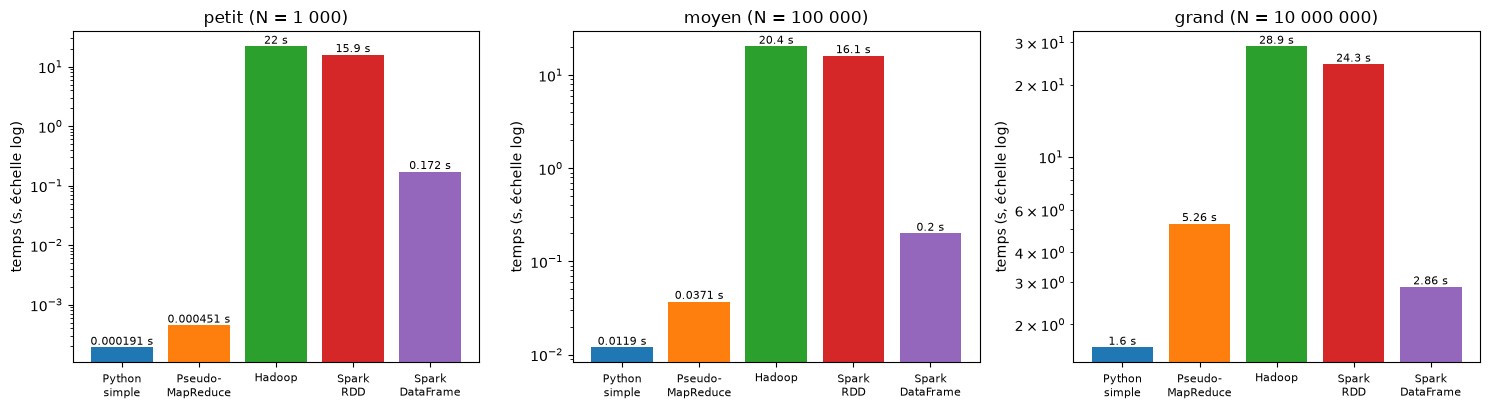

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
etiquettes = {"1. Python simple": "Python\nsimple", "2. Pseudo-MapReduce": "Pseudo-\nMapReduce",
              "3. Hadoop MapReduce": "Hadoop", "4a. Spark RDD": "Spark\nRDD", "4b. Spark DataFrame": "Spark\nDataFrame"}
for ax, nom in zip(axes, TAILLES):
    g = df_tout[df_tout["fichier"] == nom].sort_values("méthode")
    barres = ax.bar([etiquettes[m] for m in g["méthode"]], g["temps (s)"], color=[couleurs[m] for m in g["méthode"]])
    ax.bar_label(barres, fmt="%.3g s", fontsize=8)
    ax.set_title(f"{nom} (N = {TAILLES[nom]:,})".replace(",", " "))
    ax.set_yscale("log")
    ax.set_ylabel("temps (s, échelle log)")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

In [26]:
pentes_tout = {m: np.polyfit(np.log10(g["N"]), np.log10(g["temps (s)"]), 1)[0] for m, g in df_tout.groupby("méthode")}
pd.Series(pentes_tout, name="exposant b (temps ∝ N^b)").round(2).to_frame()

,exposant b (temps ∝ N^b)
1. Python simple,0.98
2. Pseudo-MapReduce,1.02
3. Hadoop MapReduce,0.03
4a. Spark RDD,0.05
4b. Spark DataFrame,0.31


### Spark RDD sous Windows

Sous Windows, PySpark lance un nouveau processus Python à chaque tâche (≈ 1 s chacun).
Test avec un job vide :

In [27]:
diag = []
for p in [1, 2, 4, 8]:
    temps = []
    for _ in range(3):
        t0 = time.perf_counter()
        sc.parallelize(range(p), p).map(lambda x: x).collect()
        temps.append(time.perf_counter() - t0)
    diag.append({"tâches Python en parallèle": p, "temps d'un job vide (s)": statistics.median(temps)})
pd.DataFrame(diag).round(2)

,tâches Python en parallèle,temps d'un job vide (s)
0,1,1.08
1,2,2.02
2,4,4.18
3,8,7.76


D'où le coût fixe de la version RDD sous Windows. On refait donc les mesures sous Linux (Docker).

### Spark sous Linux

Mêmes fonctions, exécutées dans `apache/spark:4.2.0-python3` ([`spark/comptage_spark.py`](spark/comptage_spark.py)).

In [28]:
import json
IMAGE_SPARK = "apache/spark:4.2.0-python3"

def spark_linux(coeurs, fichiers_rep):
    # Lance comptage_spark.py dans un conteneur Spark (Linux) et renvoie les mesures (une par ligne JSON)
    args = " ".join(f"/tmp/{nom}.txt:{rep}" for nom, rep in fichiers_rep)
    cmd = ["docker", "run", "--rm",
           "-v", f"{DATA.resolve()}:/donnees:ro", "-v", f"{Path('spark').resolve()}:/app:ro",
           IMAGE_SPARK, "sh", "-c",
           f"cp /donnees/*.txt /tmp/ && /opt/spark/bin/spark-submit --driver-memory 4g "
           f"/app/comptage_spark.py {coeurs} {args}"]
    r = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8")
    lignes = [json.loads(l) for l in r.stdout.splitlines() if l.startswith("{")]
    if not lignes:
        raise RuntimeError(r.stderr[-3000:])
    return lignes[0], lignes[1:]

info, mesures_linux = spark_linux(8, [("petit", 7), ("moyen", 7), ("grand", 3)])
print(f"Spark sous Linux : {info['parallélisme']} tâches en parallèle, démarrage de la session : {info['démarrage (s)']:.2f} s")
for m in mesures_linux:
    print(f"{m['fichier']:6s} {m['méthode']:22s} médiane = {m['temps (s)']:.4f} s")

Spark sous Linux : 8 tâches en parallèle, démarrage de la session : 4.58 s
petit  4a. Spark RDD          médiane = 0.3508 s
petit  4b. Spark DataFrame    médiane = 0.2340 s
moyen  4a. Spark RDD          médiane = 0.2810 s
moyen  4b. Spark DataFrame    médiane = 0.3548 s
grand  4a. Spark RDD          médiane = 6.2966 s
grand  4b. Spark DataFrame    médiane = 2.0884 s


In [29]:
dl = pd.DataFrame(mesures_linux)
dl["N"] = dl["fichier"].map(TAILLES)
dl["méthode"] = dl["méthode"] + " (Linux)"
couleurs.update({"4a. Spark RDD (Linux)": "darkred", "4b. Spark DataFrame (Linux)": "indigo"})

df_final = pd.concat([df_tout[["fichier", "N", "méthode", "temps (s)", "min (s)", "max (s)"]],
                      dl[["fichier", "N", "méthode", "temps (s)", "min (s)", "max (s)"]]], ignore_index=True)
df_final["méthode"] = df_final["méthode"].replace({"4a. Spark RDD": "4a. Spark RDD (Windows)",
                                                   "4b. Spark DataFrame": "4b. Spark DataFrame (Windows)"})
couleurs.update({"4a. Spark RDD (Windows)": couleurs["4a. Spark RDD"],
                 "4b. Spark DataFrame (Windows)": couleurs["4b. Spark DataFrame"]})
df_final["× vs méthode 1"] = df_final.apply(lambda r: r["temps (s)"] / base[r["fichier"]], axis=1)

tableau_final = df_final.pivot(index="méthode", columns="fichier", values="temps (s)")[list(TAILLES)]
tableau_final.columns = [f"{c} (N={TAILLES[c]:,})".replace(",", " ") for c in tableau_final.columns]
tableau_final.style.format("{:.4f}").highlight_min(axis=0, color="#c6efce")

,petit (N=1 000),moyen (N=100 000),grand (N=10 000 000)
méthode,,,
1. Python simple,0.0002,0.0119,1.6036
2. Pseudo-MapReduce,0.0005,0.0371,5.2605
3. Hadoop MapReduce,21.9613,20.3536,28.8764
4a. Spark RDD (Linux),0.3508,0.2810,6.2966
4a. Spark RDD (Windows),15.8911,16.1232,24.3132
4b. Spark DataFrame (Linux),0.2340,0.3548,2.0884
4b. Spark DataFrame (Windows),0.1721,0.1999,2.8643


In [30]:
df_final.pivot(index="méthode", columns="fichier", values="× vs méthode 1")[list(TAILLES)].round(2)

fichier,petit,moyen,grand
méthode,,,
1. Python simple,1.00,1.00,1.00
2. Pseudo-MapReduce,2.36,3.11,3.28
3. Hadoop MapReduce,114860.32,1706.63,18.01
4a. Spark RDD (Linux),1834.73,23.56,3.93
4a. Spark RDD (Windows),83112.40,1351.92,15.16
4b. Spark DataFrame (Linux),1223.61,29.75,1.30
4b. Spark DataFrame (Windows),899.99,16.76,1.79


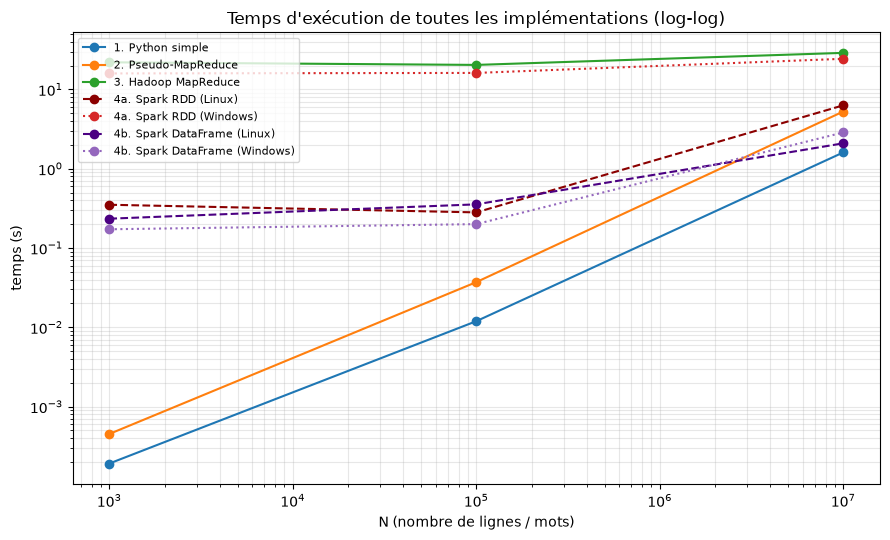

In [31]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for methode, g in df_final.groupby("méthode"):
    g = g.sort_values("N")
    style = ":" if "Windows" in methode else ("--" if methode.startswith("4") else "-")
    ax.plot(g["N"], g["temps (s)"], marker="o", ls=style, label=methode, color=couleurs[methode])
ax.set(xscale="log", yscale="log", xlabel="N (nombre de lignes / mots)", ylabel="temps (s)",
       title="Temps d'exécution de toutes les implémentations (log-log)")
ax.grid(True, which="both", alpha=.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Nombre de cœurs (grand fichier)

In [32]:
spark.stop()
paral = []
for k in [1, 2, 4, 8]:
    spark = demarrer_spark(k)
    spark.sparkContext.setLogLevel("ERROR")
    sc = spark.sparkContext
    methode4_rdd(FICHIERS["petit"]); methode4_df(FICHIERS["petit"])   # échauffement
    for methode, f in [("4a. Spark RDD", methode4_rdd), ("4b. Spark DataFrame", methode4_df)]:
        med, _ = chrono(f, FICHIERS["grand"], 3)
        paral.append({"cœurs": k, "méthode": f"{methode} (Windows)", "temps (s)": med})
    spark.stop()

    if k == 8:   # déjà mesuré à la section 13
        mesures_k = [m for m in mesures_linux if m["fichier"] == "grand"]
    else:
        _, mesures_k = spark_linux(k, [("grand", 3)])
    for m in mesures_k:
        paral.append({"cœurs": k, "méthode": f"{m['méthode']} (Linux)", "temps (s)": m["temps (s)"]})
    print(f"local[{k}] mesuré")

dp = pd.DataFrame(paral)
dp["accélération"] = dp.apply(
    lambda r: dp[(dp["méthode"] == r["méthode"]) & (dp["cœurs"] == 1)]["temps (s)"].iloc[0] / r["temps (s)"], axis=1)
dp.pivot(index="cœurs", columns="méthode", values=["temps (s)", "accélération"]).round(2)

local[1] mesuré


local[2] mesuré


local[4] mesuré


local[8] mesuré


temps (s)                          \
méthode 4a. Spark RDD (Linux) 4a. Spark RDD (Windows)   
cœurs                                                   
1                       15.14                   21.72   
2                        8.81                   17.05   
4                        7.11                   22.19   
8                        6.30                   26.08   

                                                                   \
méthode 4b. Spark DataFrame (Linux) 4b. Spark DataFrame (Windows)   
cœurs                                                               
1                              5.54                          5.19   
2                              3.38                          3.75   
4                              3.00                          3.20   
8                              2.09                          2.66   

                 accélération                          \
méthode 4a. Spark RDD (Linux) 4a. Spark RDD (Windows)   
cœurs                                                   
1                        1.00                    1.00   
2                        1.72                    1.27   
4                        2.13                    0.98   
8                        2.40                    0.83   

                                                                   
méthode 4b. Spark DataFrame (Linux) 4b. Spark DataFrame (Windows)  
cœurs                                                              
1                              1.00                          1.00  
2                              1.64                          1.38  
4                              1.84                          1.62  
8                              2.65                          1.95

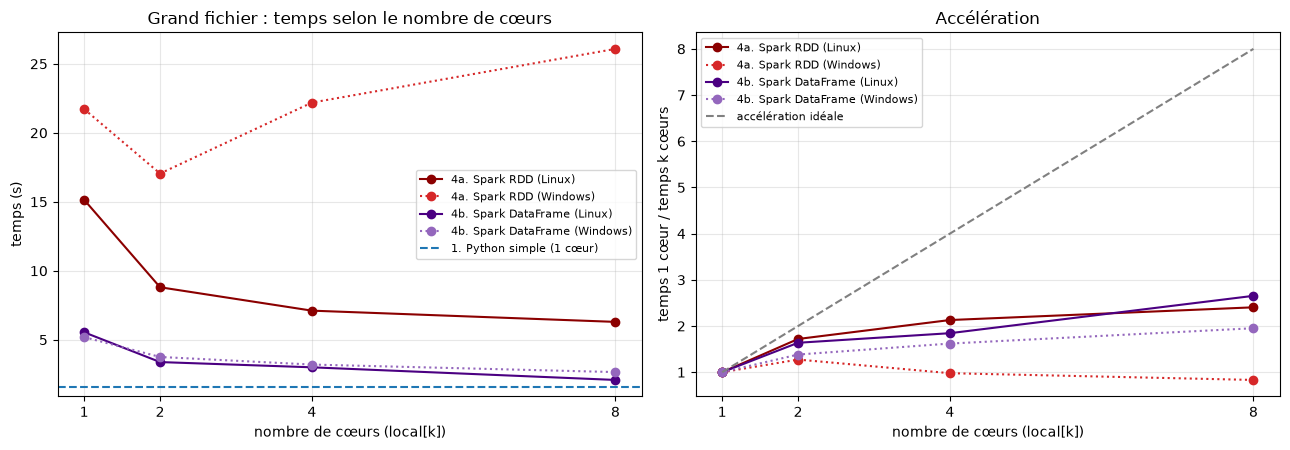

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for methode, g in dp.groupby("méthode"):
    style = ":" if "Windows" in methode else "-"
    axes[0].plot(g["cœurs"], g["temps (s)"], marker="o", ls=style, label=methode, color=couleurs[methode])
    axes[1].plot(g["cœurs"], g["accélération"], marker="o", ls=style, label=methode, color=couleurs[methode])
axes[0].axhline(base["grand"], color=couleurs["1. Python simple"], ls="--", label="1. Python simple (1 cœur)")
axes[1].plot([1, 8], [1, 8], color="grey", ls="--", label="accélération idéale")
axes[0].set(xlabel="nombre de cœurs (local[k])", ylabel="temps (s)", title="Grand fichier : temps selon le nombre de cœurs")
axes[1].set(xlabel="nombre de cœurs (local[k])", ylabel="temps 1 cœur / temps k cœurs", title="Accélération")
for ax in axes:
    ax.set_xticks([1, 2, 4, 8])
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Conclusion

| Méthode | Petit (1 000) | Grand (10 M) |
|---|---:|---:|
| Python simple | 0,2 ms | 1,6 s |
| Pseudo-MapReduce | 0,5 ms | 5,3 s |
| Hadoop MapReduce | 22 s | 29 s |
| Spark RDD (Linux) | 0,35 s | 6,3 s |
| Spark DataFrame (Linux) | 0,23 s | 2,1 s |

- Tant que les données tiennent en mémoire, **Python simple** reste le plus rapide.
- **Spark** est ≈ 14 × plus rapide que Hadoop sur le grand fichier, avec un coût fixe de ≈ 0,3 s contre ≈ 20 s.
  Il garde les données en mémoire et ne lance pas de conteneurs YARN.
- **DataFrame** est plus rapide que **RDD**, car le calcul reste dans la JVM, sans passer par Python.
- Spark profite des cœurs : × 2,65 entre 1 et 8 cœurs (DataFrame). Hadoop n'en utilise qu'un ici.
- Sous Windows, les RDD PySpark sont très lents (un processus Python par tâche).
- Hadoop et Spark sont faits pour des volumes qui dépassent une seule machine. À cette échelle, ils ne battent pas Python.